# Task 3 – Notebook 3: DNN resource allocation (unsupervised)
MLP (input 8x16 gains in dB + $P_{\max}$ in dBm, two hidden layers of 512 ReLU units). Outputs: (a) assignment logits per RB, softmax over users, hard arg-max at test time (straight-through gradient in training) – each RB gets exactly one user; (b) power fractions via softmax, $p_n=P_{\max}\,\mathrm{softmax}_n$ – non-negative and summing to the budget.

Loss: $L=-\text{SumRate}[\text{Mbps}]+\lambda\sum_u\max(0,1-R_u[\text{Mbps}])^2$, $\lambda=5$. Trained on freshly generated channels with $P_{\max}\sim U(15,40)$ dBm, **no MILP labels**. Note: $P_{\max}$ is given as an additional scalar input (one model for the whole sweep); the assignment text lists only $H$. $\lambda$ and size were chosen from short trials on held-out drops (λ∈{5,10,20,60}, hidden 256/512).

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().resolve().parents[1]
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
torch.set_num_threads(1)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
from task3_resource.system import P, dbm_to_w, draw_channels, rb_rates, user_rates, POWER_DBM_GRID
from task3_resource import allocation as al, dnn, experiments as ex
T = ex.RES / "tables"; F = ex.RES / "figures"


{
  "steps": 12000,
  "batch": 512,
  "lr": 0.001,
  "lam": 5.0,
  "seed": 20241114,
  "hidden": 512
}
parameters: 403088


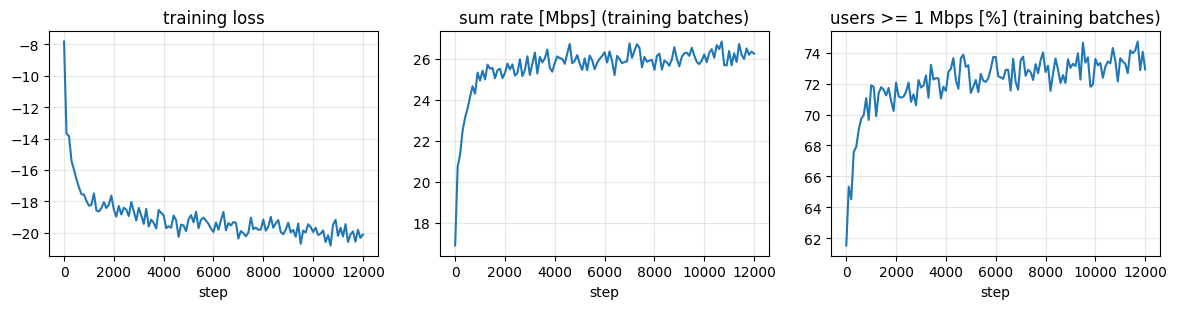

In [2]:
net = dnn.load(ex.MODELS / "dnn_alloc.pt")
print(open(ex.MODELS / "dnn_alloc.json").read())
print("parameters:", sum(p.numel() for p in net.parameters()))
h = pd.read_csv(T / "dnn_training_history.csv")
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
ax[0].plot(h.step, h.loss); ax[0].set_title("training loss"); ax[1].plot(h.step, h.sum_rate_mbps); ax[1].set_title("sum rate [Mbps] (training batches)")
ax[2].plot(h.step, 100*h.qos_satisfied); ax[2].set_title("users >= 1 Mbps [%] (training batches)")
for x_ in ax: x_.set_xlabel("step"); x_.grid(alpha=.3)
fig.tight_layout(); fig.savefig(F / "dnn_training_curves.png", dpi=150); plt.show()

### Validity and QoS check on 200 fresh test drops (not seen in training)

In [3]:
V = draw_channels(200, np.random.default_rng(424242))
rows = []
for pdbm in [15, 20, 25, 30, 35, 40]:
    pmax = dbm_to_w(pdbm); ok = True; S = []; Q = []; AQ = []; Sm = []; Qm = []
    for a in V:
        x, pw, _ = dnn.predict(net, a, pmax)
        ok &= bool((x.sum(0) == 1).all() and (pw >= 0).all() and pw.sum() <= pmax*(1+1e-9) and x.shape == (8, 16) and pw.shape == (16,))
        R = user_rates(x, pw, a); S.append(R.sum()/1e6); Q.append((R >= 1e6).mean()); AQ.append((R >= 1e6).all())
        xm, pm, _ = al.milp_equal_power(a, pmax); Rm = user_rates(xm, pm, a); Sm.append(Rm.sum()/1e6); Qm.append((Rm >= 1e6).mean())
    rows.append({"P_max [dBm]": pdbm, "all outputs valid": ok, "DNN sum rate": np.mean(S), "MILP sum rate": np.mean(Sm), "DNN users>=1Mbps [%]": 100*np.mean(Q),
                 "MILP users>=1Mbps [%]": 100*np.mean(Qm), "DNN drops with all users OK [%]": 100*np.mean(AQ)})
dv = pd.DataFrame(rows).round(2); dv.to_csv(T / "task3_dnn_validity_check.csv", index=False); dv

,P_max [dBm],all outputs valid,DNN sum rate,MILP sum rate,DNN users>=1Mbps [%],MILP users>=1Mbps [%],DNN drops with all users OK [%]
0,15,True,17.23,13.19,47.12,76.06,0.0
1,20,True,20.95,16.15,58.19,89.31,0.0
2,25,True,24.83,21.29,69.88,96.81,3.5
3,30,True,28.79,27.89,78.56,99.38,8.0
4,35,True,32.67,34.56,85.69,100.00,24.0
5,40,True,36.87,40.47,89.31,100.00,34.0


QoS violations of the standalone DNN are **reported** above (columns 'users>=1Mbps' and 'drops with all users OK'); nothing is post-processed here. The hybrid method of notebook 4 repairs the power allocation.